# Reproduce the paper: tributary flash-flood forecast points on the Rwenzori and Nombe–Karugutu escarpments

**Kakooza, C. and Nafula, M. (2026).** *Soil-moisture-dependent flash flood guidance for ungauged escarpment tributaries in an operational HEC-RTS forecasting system: the Semliki Basin, Uganda.* Zenodo.

Run it top to bottom (*Run all*). It needs `numpy`, `pandas`, `scipy` and `matplotlib`, takes under a minute, and runs
locally or in Google Colab. Every number of the paper's tables is recomputed from the files in `data/`.

| Step | Reproduces |
|---|---|
| 1 | the forecast-point catchments (Table 1) |
| 2 | the 95th and 99th percentiles of catchment-mean daily rain and their October–December frequency (Table 2, Fig. 2) |
| 3 | the River Wassa rain return levels (Gumbel, maximum likelihood) and the frequency of the proposed levels (Table 3) |
| 4 | the H60B scale factors, the over-reading of H60B and the ranks of 20 November 2026 (Table 4, Fig. 4) |
| 5 | the flash flood guidance of the issue of 20 November 2026 from the HEC-HMS states (Table 6, Fig. 6) |
| 6 | the check of the guidance model against HEC-HMS (Table 5) and the escarpment calibration test (Table 7) |
| 7 | the rolling hydrograph and the rainfall figure of the River Wassa for the same issue (Fig. 5) |

The HEC-HMS model itself and the gauge records are not distributed here (requests to the corresponding author); `data/ffg_inputs_20261120.json` carries the parameters and states the guidance needs.

## 0. Set-up

In [1]:
import os, sys, json, zipfile, urllib.request
RAW = "https://raw.githubusercontent.com/Kaitale/semliki-sem9.12-flash-flood-guidance/main/"
for f in ("semliki_ffg.py", "data_tributary_points.zip"):
    if not os.path.exists(f):
        print("downloading", f); urllib.request.urlretrieve(RAW + f, f)
if not os.path.isdir("data"):
    zipfile.ZipFile("data_tributary_points.zip").extractall(".")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy.stats import gumbel_r
sys.path.insert(0, os.path.abspath("."))
import semliki_ffg as F
OUT = os.path.abspath("outputs"); os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6EBEF"})
J = lambda f: json.load(open(os.path.join("data", f)))

## 1. The catchments of the forecast points (Table 1)

In [2]:
cat = pd.read_csv("data/catchments.csv"); cat

,catchment,subbasins,area_km2
0,Ndugutu,Ndugutu Ndugutu-Upper Swamp-Local,507.17
1,Tokwe,Tokwe,188.53
2,Sempaya-Burondo (S33),S33,239.38
3,All Bundibugyo slopes,Ndugutu Ndugutu-Upper Swamp-Local Tokwe S33,935.08
4,River Wassa at Karugutu,S34 S11,242.05
5,Wassa and east-bank tributaries at the Semliki...,S11 S12 S30 S31 S32 S34 S63 S8,1185.80
6,Semliki at Lake Albert (local rain below Bwera...,S11 S12 S2 S26 S29 S30 S31 S32 S34 S4 S47 S48 ...,3282.27


## 2. Rainfall percentiles (Table 2, Fig. 2)

Catchment-mean daily rain from bias-corrected CHIRPS per HEC-HMS subbasin, area-weighted, 1981–2025 (all days, dry days
included). The thresholds of each forecast member are the same seasonal quantile of the member's own record.

In [3]:
R = pd.read_csv("data/chirps_bc_catchment_daily_1981_2025.csv", index_col=0, parse_dates=True)
ond = R[R.index.month.isin([10, 11, 12])]; ny = R.index.year.nunique()
T2 = pd.DataFrame({"P95_mm": R.quantile(.95), "P99_mm": R.quantile(.99), "max_mm": R.max(),
                   "OND_days_ge_P95_per_season": (ond >= R.quantile(.95)).sum() / ny,
                   "OND_days_ge_P99_per_season": (ond >= R.quantile(.99)).sum() / ny}).round(1)
T2.to_csv(os.path.join(OUT, "table2_percentiles.csv")); T2

,P95_mm,P99_mm,max_mm,OND_days_ge_P95_per_season,OND_days_ge_P99_per_season
Ndugutu,16.6,25.9,69.1,6.1,1.3
Tokwe,17.2,27.2,69.2,5.8,1.1
Sempaya-Burondo (S33),17.1,26.6,64.6,6.4,1.2
All Bundibugyo slopes,16.6,25.6,68.0,5.9,1.1
River Wassa at Karugutu,16.6,26.1,59.4,6.3,1.1
Wassa and east-bank tributaries at the Semliki (JS3),15.4,24.8,57.1,6.2,1.1
Semliki at Lake Albert (local rain below Bweramule),15.3,23.9,55.1,6.2,1.2


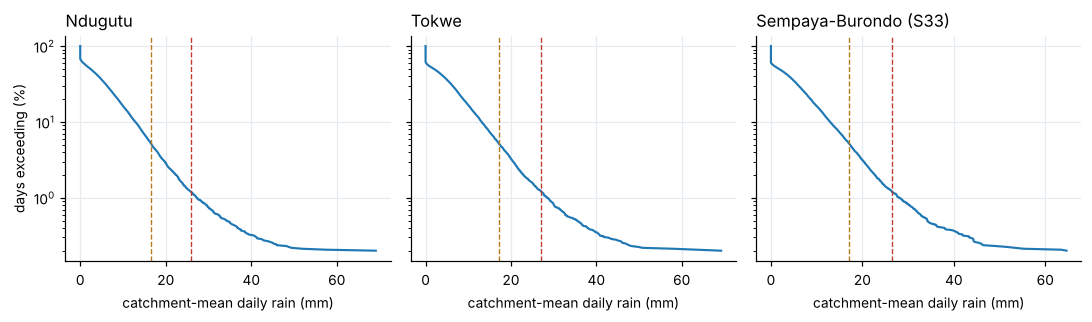

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, c in zip(axs, ["Ndugutu", "Tokwe", "Sempaya-Burondo (S33)"]):
    v = np.sort(R[c].values)[::-1]; p = np.arange(1, len(v) + 1) / (len(v) + 1) * 100
    ax.semilogy(v, p, lw=1.4); ax.set_title(c, loc="left")
    for q, col in ((.95, "#B7791F"), (.99, "#C0392B")):
        ax.axvline(R[c].quantile(q), color=col, ls="--", lw=.9)
    ax.set_xlabel("catchment-mean daily rain (mm)")
axs[0].set_ylabel("days exceeding (%)"); fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig2_exceedance.png"), dpi=200)

## 3. River Wassa: return levels and the proposed levels (Table 3)

Annual maxima of 1-day and 3-day rain on S34 + S11, Gumbel fitted by maximum likelihood. An episode is a run of
consecutive days on which the level is met (1-day or 3-day).

In [5]:
w = R["River Wassa at Karugutu"]; w3 = w.rolling(3).sum()
rows = []
for lab, s in (("1-day", w), ("3-day", w3)):
    am = s.groupby(s.index.year).max().dropna(); loc, sc = gumbel_r.fit(am.values)
    rows.append([lab] + [round(gumbel_r.ppf(1 - 1 / T, loc, sc), 1) for T in (2, 5, 10, 25)])
T3a = pd.DataFrame(rows, columns=["duration", "T2", "T5", "T10", "T25"]); display(T3a)
L = J("wassa_levels.json")["rain_triggers_mm"]; res = []
for lev in ("watch", "warning"):
    hit = (w >= L[lev]["one_day"]) | (w3 >= L[lev]["three_day"])
    ep = int((hit & ~hit.shift(1, fill_value=False)).sum())
    res.append([lev, L[lev]["one_day"], L[lev]["three_day"], ep, round(ep / 45, 1), int(hit.groupby(hit.index.year).any().sum())])
T3b = pd.DataFrame(res, columns=["level", "1-day mm", "3-day mm", "episodes 1981-2025", "per year", "years with an episode"])
for ev, (a, b) in {"Oct 2022": ("2022-10-01", "2022-10-31"), "Oct-Dec 2014": ("2014-10-01", "2014-12-31"), "Jul-Dec 2024": ("2024-07-01", "2024-12-31")}.items():
    print("%-13s wettest day %.1f mm, wettest 3 days %.1f mm" % (ev, w[a:b].max(), w3[a:b].max()))
T3a.to_csv(os.path.join(OUT, "table3_return_levels.csv"), index=False); T3b.to_csv(os.path.join(OUT, "table3_levels_frequency.csv"), index=False); T3b

,duration,T2,T5,T10,T25
0,1-day,36.3,45.1,51.0,58.4
1,3-day,60.9,74.0,82.7,93.6


Oct 2022      wettest day 24.5 mm, wettest 3 days 49.3 mm
Oct-Dec 2014  wettest day 17.1 mm, wettest 3 days 39.1 mm
Jul-Dec 2024  wettest day 53.4 mm, wettest 3 days 80.7 mm


,level,1-day mm,3-day mm,episodes 1981-2025,per year,years with an episode
0,watch,26,45,261,5.8,45
1,warning,36,61,59,1.3,27


## 4. H60B on the forecast points (Table 4, Fig. 4)

H60B day *d* is the 24 h to 08:15 EAT on day *d* (≈ UTC day *d* − 1). The scale factor *k* is the bias-corrected IMERG Late
total over the common days divided by the H60B total, bounded 0.3–2.

In [6]:
H = pd.read_csv("data/h60b_catchment_daily.csv", index_col=0, parse_dates=True)
I = pd.read_csv("data/imerg_late_catchment_daily.csv", index_col=0, parse_dates=True)
mf = J("imerg_late_monthly_factor.json")["imerg_late_bias_factor_by_month"]
Ib = I.mul(pd.Series([mf.get(t.strftime("%b"), 1.0) for t in I.index], index=I.index), axis=0); Ib.index = Ib.index + pd.Timedelta(days=1)
t = pd.Timestamp("2026-11-20"); rows = []
for c in H.columns:
    j = pd.concat([H[c], Ib[c]], axis=1, keys=["h", "i"], sort=True).dropna()
    k = float(np.clip(j.i.sum() / j.h.sum(), 0.3, 2.0))
    on = R[c][R.index.month.isin([10, 11])]
    rows.append([c, len(j), round(k, 2), round(j.corr().iloc[0, 1], 2), round(H[c].mean(), 1), round(on.mean(), 1),
                 round(100 * (H[c] >= 26).mean(), 1), round(100 * (on >= 26).mean(), 1),
                 H.at[t, c], round(H.at[t, c] * k, 1), int((H[c][:t] > H.at[t, c]).sum()) + 1])
T4 = pd.DataFrame(rows, columns=["catchment", "common days", "k", "r", "H60B mean mm/d", "CHIRPS Oct-Nov mean", "H60B % days >=26",
                                 "CHIRPS % days >=26", "20 Nov raw", "20 Nov scaled", "rank of 20 Nov"])
T4.to_csv(os.path.join(OUT, "table4_h60b.csv"), index=False); T4

,catchment,common days,k,r,H60B mean mm/d,CHIRPS Oct-Nov mean,H60B % days >=26,CHIRPS % days >=26,20 Nov raw,20 Nov scaled,rank of 20 Nov
0,Ndugutu,45,0.43,0.40,11.8,6.6,10.9,1.3,16.4,7.0,14
1,Tokwe,45,0.44,0.34,11.8,6.4,15.2,1.4,25.8,11.4,8
2,Sempaya-Burondo (S33),45,0.44,0.40,11.4,6.4,15.2,1.6,30.1,13.3,5
3,All Bundibugyo slopes,45,0.43,0.41,11.7,6.5,10.9,1.1,21.7,9.4,8
4,River Wassa at Karugutu,45,0.39,0.37,12.3,6.7,13.0,1.5,36.4,14.1,1
5,Wassa and east-bank tributaries at the Semliki...,45,0.36,0.14,11.3,6.3,10.9,1.3,34.0,12.3,1
6,Semliki at Lake Albert (local rain below Bwera...,45,0.41,0.24,10.4,6.1,6.5,1.2,28.3,11.6,3


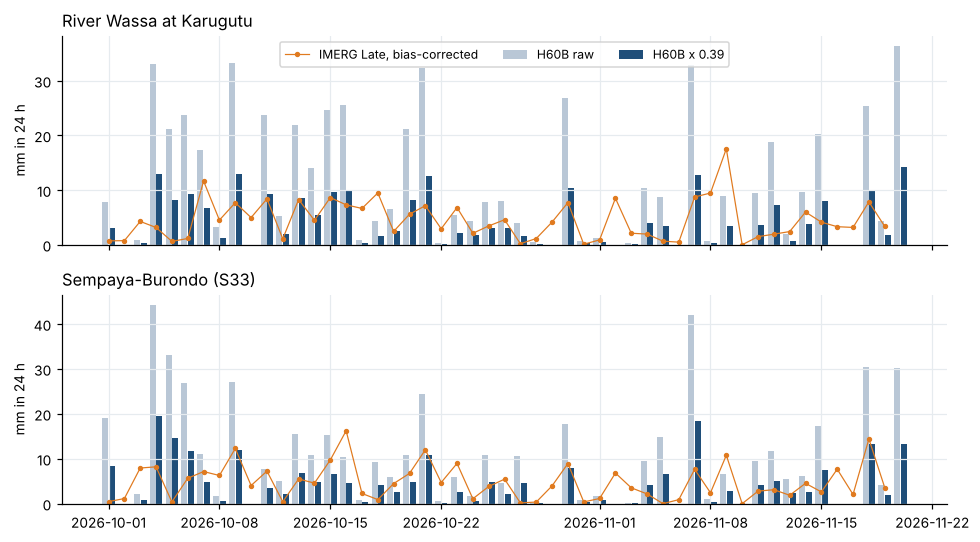

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for ax, c in zip(axs, ["River Wassa at Karugutu", "Sempaya-Burondo (S33)"]):
    k = float(T4.set_index("catchment").at[c, "k"])
    ax.bar(H.index - pd.Timedelta(hours=5), H[c], .38, color="#B9C7D6", label="H60B raw")
    ax.bar(H.index + pd.Timedelta(hours=5), H[c] * k, .38, color="#1F4E79", label="H60B x %.2f" % k)
    ib = Ib[c]["2026-10-01":]; ax.plot(ib.index, ib.values, "o-", ms=2.5, lw=.8, color="#E07A1F", label="IMERG Late, bias-corrected")
    ax.set_title(c, loc="left"); ax.set_ylabel("mm in 24 h")
axs[0].legend(ncol=3, fontsize=8); fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig4_h60b.png"), dpi=200)

## 5. Flash flood guidance, issue of 20 November 2026 (Table 6, Fig. 6)

`semliki_ffg.py` reproduces the HEC-HMS Deficit-and-Constant loss, the Clark unit hydrograph and the two linear
groundwater reservoirs; the guidance is the uniform rain over *d* hours that brings the point from its flow at the issue
to its level, found by bisection.

In [8]:
G = J("ffg_inputs_20261120.json"); pub = {p["element"]: p for p in J("ffg_issue_20261120.json")["points"]}
rows = []
for p in G["points"]:
    P, S = p["parameters"], p["state"]; (n1, l1), (n2, l2) = list(p["levels"].items())
    g = {d: (F.guidance(l1, d, P, S, p["flow_at_issue"]), F.guidance(l2, d, P, S, p["flow_at_issue"])) for d in (1, 3, 6, 12, 24)}
    A = sum(P[s]["area"] for s in P); dpct = 100 * sum(S[s]["deficit"] * P[s]["area"] for s in P) / sum(P[s]["maxdef"] * P[s]["area"] for s in P)
    same = all(abs((g[d][0] or 0) - (pub[p["element"]]["guidance_mm"][str(d)]["watch"] or 0)) < 0.15 for d in (1, 3, 6, 24))
    rows.append([p["point"], round(A), "%s %.1f" % (n1, l1), p["flow_at_issue"], round(dpct)] + [g[d][0] for d in (1, 3, 6, 12, 24)] + [g[d][1] for d in (1, 3, 24)] + [same])
T6 = pd.DataFrame(rows, columns=["point", "km2", "first level", "flow at issue", "deficit %", "L1 1h", "L1 3h", "L1 6h", "L1 12h", "L1 24h",
                                 "L2 1h", "L2 3h", "L2 24h", "as published"])
T6.to_csv(os.path.join(OUT, "table6_guidance.csv"), index=False); T6

,point,km2,first level,flow at issue,deficit %,L1 1h,L1 3h,L1 6h,L1 12h,L1 24h,L2 1h,L2 3h,L2 24h,as published
0,River Wassa at Karugutu,242,Watch 9.7,5.973,0,20.1,30.0,30.5,31.5,33.9,22.9,43.9,57.7,True
1,Ndugutu (Bundibugyo),507,P95 16.8,12.968,0,17.7,17.7,17.8,18.0,18.8,22.6,36.2,38.4,True
2,Tokwe (Bundibugyo),189,P95 6.5,5.284,0,17.2,17.2,17.3,17.6,18.2,23.7,36.0,38.2,True
3,Sempaya-Burondo (S33),239,P95 8.2,6.439,0,18.6,18.7,18.8,19.1,19.9,21.6,36.8,39.3,True


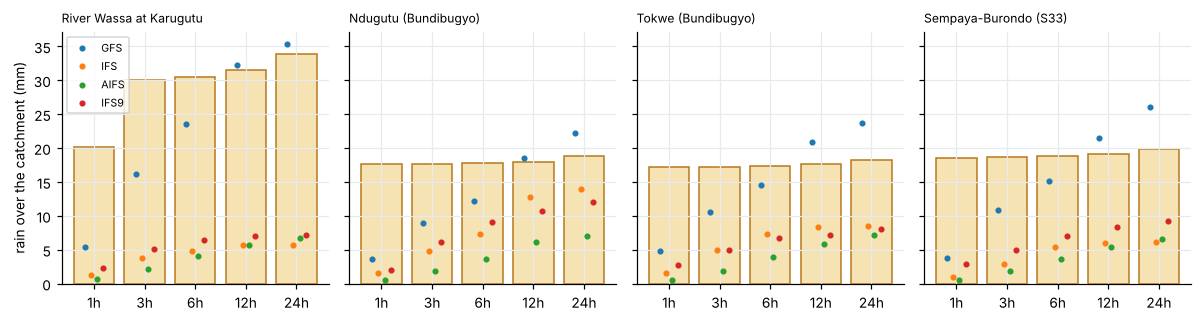

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(11, 3), sharey=True); D = [1, 3, 6, 12, 24]
for ax, r in zip(axs, T6.itertuples()):
    ax.bar(range(5), [r[6], r[7], r[8], r[9], r[10]], color="#F6E3B4", edgecolor="#B7791F")
    mem = pub[[p["element"] for p in G["points"]][r.Index]]["members"]
    for i, (m, v) in enumerate(mem.items()):
        ax.plot(np.arange(5) + (i - 1.5) * .12, [v["wettest"][str(d)]["mm"] for d in D], "o", ms=3, label=m)
    ax.set_xticks(range(5)); ax.set_xticklabels(["%dh" % d for d in D]); ax.set_title(r.point, loc="left", fontsize=8)
axs[0].set_ylabel("rain over the catchment (mm)"); axs[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig6_guidance.png"), dpi=200)

### Sensitivity of the guidance to the constant rate and the fast response (Section 4.4)

The same levels, the same state; the constant rate halved, or the faster response supported by the hourly radar record on the
main river (Clark R × 0.11, Tc × 0.57, impervious share 8 %, quick groundwater fraction 0.12, maximum deficit × 0.746).

In [10]:
import copy
def mod(P, kind):
    Q = copy.deepcopy(P)
    for p in Q.values():
        if kind == "fast": p.update(imperv=0.08, r=p["r"] * 0.11, tc=p["tc"] * 0.566, gw1f=0.12, gw2f=0.88, perc=p["perc"] * 0.944, maxdef=p["maxdef"] * 0.746)
        if kind == "constant rate x 0.5": p["perc"] *= 0.5
    return Q
rows = []
for p in G["points"]:
    l1 = list(p["levels"].values())[0]
    for kind in ("present", "constant rate x 0.5", "fast"):
        P = mod(p["parameters"], kind); rows.append([p["point"], kind] + [F.guidance(l1, d, P, p["state"], p["flow_at_issue"]) for d in (1, 3, 6, 24)])
TS = pd.DataFrame(rows, columns=["point", "model", "L1 1h", "L1 3h", "L1 6h", "L1 24h"]); TS.to_csv(os.path.join(OUT, "table_guidance_sensitivity.csv"), index=False); TS

,point,model,L1 1h,L1 3h,L1 6h,L1 24h
0,River Wassa at Karugutu,present,20.1,30.0,30.5,33.9
1,River Wassa at Karugutu,constant rate x 0.5,14.7,25.3,30.5,33.9
2,River Wassa at Karugutu,fast,6.3,6.5,7.1,15.0
3,Ndugutu (Bundibugyo),present,17.7,17.7,17.8,18.8
4,Ndugutu (Bundibugyo),constant rate x 0.5,13.6,17.7,17.8,18.8
5,Ndugutu (Bundibugyo),fast,4.4,4.4,4.6,7.7
6,Tokwe (Bundibugyo),present,17.2,17.2,17.3,18.2
7,Tokwe (Bundibugyo),constant rate x 0.5,14.5,17.2,17.3,18.2
8,Tokwe (Bundibugyo),fast,4.5,4.5,4.6,6.9
9,Sempaya-Burondo (S33),present,18.6,18.7,18.8,19.9


## 6. The guidance model against HEC-HMS (Table 5) and the escarpment calibration test (Table 7)

In [11]:
V = pd.DataFrame(J("ffg_check_against_hechms.json")["cases"]).T
V["difference_%"] = (100 * (V.analytic_peak_increase / V.hms_peak_increase - 1)).astype(float).round(0); display(V)
E = J("escarpment_calibration_test.json")
T7 = pd.DataFrame([dict(**g["p"], **g["s"]) for g in E["grid"]]).sort_values("obj", ascending=False)
print("score range %.3f-%.3f; present parameters %.3f" % (T7.obj.min(), T7.obj.max(), E["present_parameters"]["obj"]))
T7.to_csv(os.path.join(OUT, "table7_escarpment_test.csv"), index=False); T7.head()

,start,hours,mm,deficit_mm,hms_peak_increase,hms_peak_after_h,analytic_peak_increase,analytic_peak_after_h,storm_alone,difference_%
A,2026-11-07 14:00,3,40.0,"{'S34': 0.0, 'S11': 0.0}",5.72,13,5.15,13,5.15,-10.0
B,2026-10-02 12:00,1,30.0,"{'S34': 35.4, 'S11': 62.3}",2.27,12,2.29,12,2.24,1.0
C,2026-11-12 06:00,6,60.0,"{'S34': 0.0, 'S11': 0.0}",7.63,15,7.61,15,7.61,-0.0


score range 0.245-0.279; present parameters 0.276


,r,gw1f,gw1k,tokwe,tokwe_d,ndugutu,ndugutu_d,obj
13,3.0,0.24377,1.0,0.538,0.060,0.360,0.157,0.279
7,1.0,0.24377,1.0,0.535,0.044,0.361,0.165,0.276
14,3.0,0.24377,3.0,0.555,0.068,0.324,0.158,0.276
6,1.0,0.24377,0.3,0.514,0.041,0.366,0.174,0.274
12,3.0,0.24377,0.3,0.516,0.041,0.367,0.163,0.272


## 7. The River Wassa, issue of 20 November 2026 (Fig. 5)

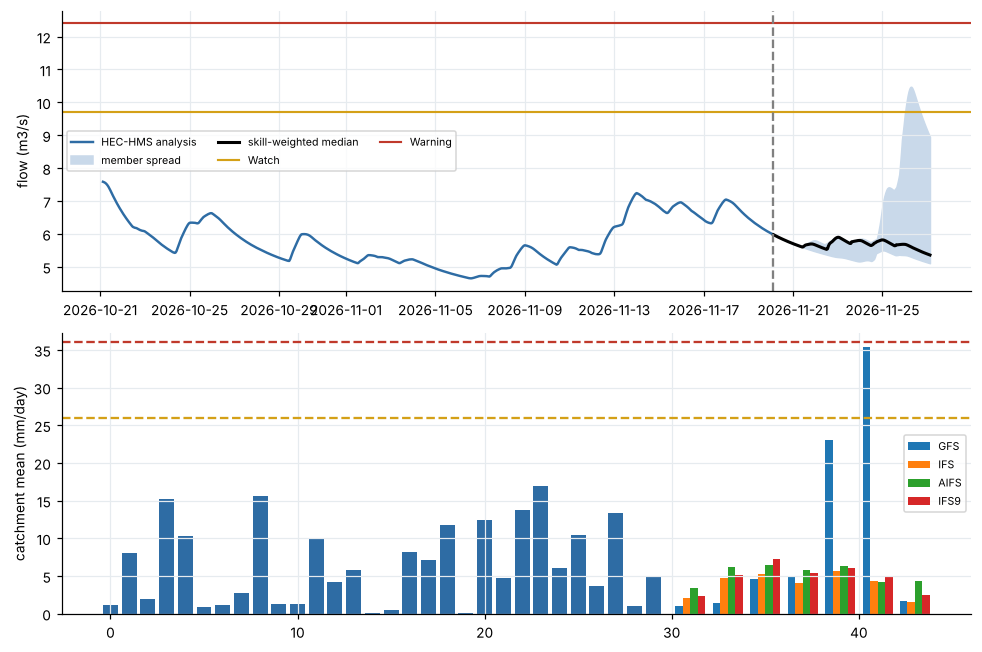

In [12]:
q = pd.read_csv("data/issue_20261120/River_Wassa_flow.csv", index_col=0, parse_dates=True)
r = pd.read_csv("data/issue_20261120/River_Wassa_rain.csv", index_col=0, parse_dates=True)
issue = pd.Timestamp("2026-11-20 03:00"); mem = [m for m in ("GFS", "IFS", "AIFS", "IFS9") if m in q]
fig, (a, b) = plt.subplots(2, 1, figsize=(9, 6))
a.plot(q.index, q.analysis, color="#2E6CA4", lw=1.6, label="HEC-HMS analysis")
a.fill_between(q.index, q[mem].min(axis=1), q[mem].max(axis=1), color="#C9D9EA", label="member spread")
a.plot(q.index, q.weighted_median, color="k", lw=2, label="skill-weighted median")
for v, c, n in ((9.7, "#D4A017", "Watch"), (12.4, "#C0392B", "Warning")): a.axhline(v, color=c, lw=1.4, label=n)
a.axvline(issue, color="grey", ls="--"); a.set_ylabel("flow (m3/s)"); a.legend(ncol=3, fontsize=7)
obs = r.measured[r.index < issue.normalize()].tail(30); fc = r.loc[r.index >= issue.normalize(), mem].head(7)
b.bar(range(len(obs)), obs.values, color="#2E6CA4")
for i, m in enumerate(mem): b.bar(len(obs) + 0.5 + 2 * np.arange(len(fc)) + 0.5 + (i - 1.5) * 0.4, fc[m].values, 0.4, label=m)
b.axhline(26, color="#D4A017", ls="--"); b.axhline(36, color="#C0392B", ls="--"); b.set_ylabel("catchment mean (mm/day)"); b.legend(fontsize=7)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig5_wassa_issue.png"), dpi=200)

Everything written by this notebook is in `outputs/`.